# Polymers 2: chain dynamics

Course assignment. An off-lattice worm-like chain diffuses freely, inside a confined volume, or relaxes from a fully stretched state. The questions are the ones given in the assignment. `PolymerFun.py` and `PolymerFun2.py` (chain generation, `DiffusionStep`, MSD, confinement volumes) were provided by the course.

Q1: Polymer diffusion. A polymer chain is randomly generate and let diffuse. At every simulation step the position of the center of mass can be stored in a container array, from which the mean square displacement for the time trace can be computed. Study if the polymer diffusion scales with polymer length and/or with the polymer compaction (changing the chi parameter).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylab
from mpl_toolkits.mplot3d import Axes3D ## import to plot polymer conformations in 3D
import random
from tqdm import tqdm 

import importlib
import PolymerFun as pf
import PolymerFun2 as pf2
importlib.reload(pf)
importlib.reload(pf2)

%matplotlib inline

plt.close('all')

# fixed seed so that the numbers quoted in the text can be reproduced
np.random.seed(1)


L=50 done


L=100 done


L=200 done


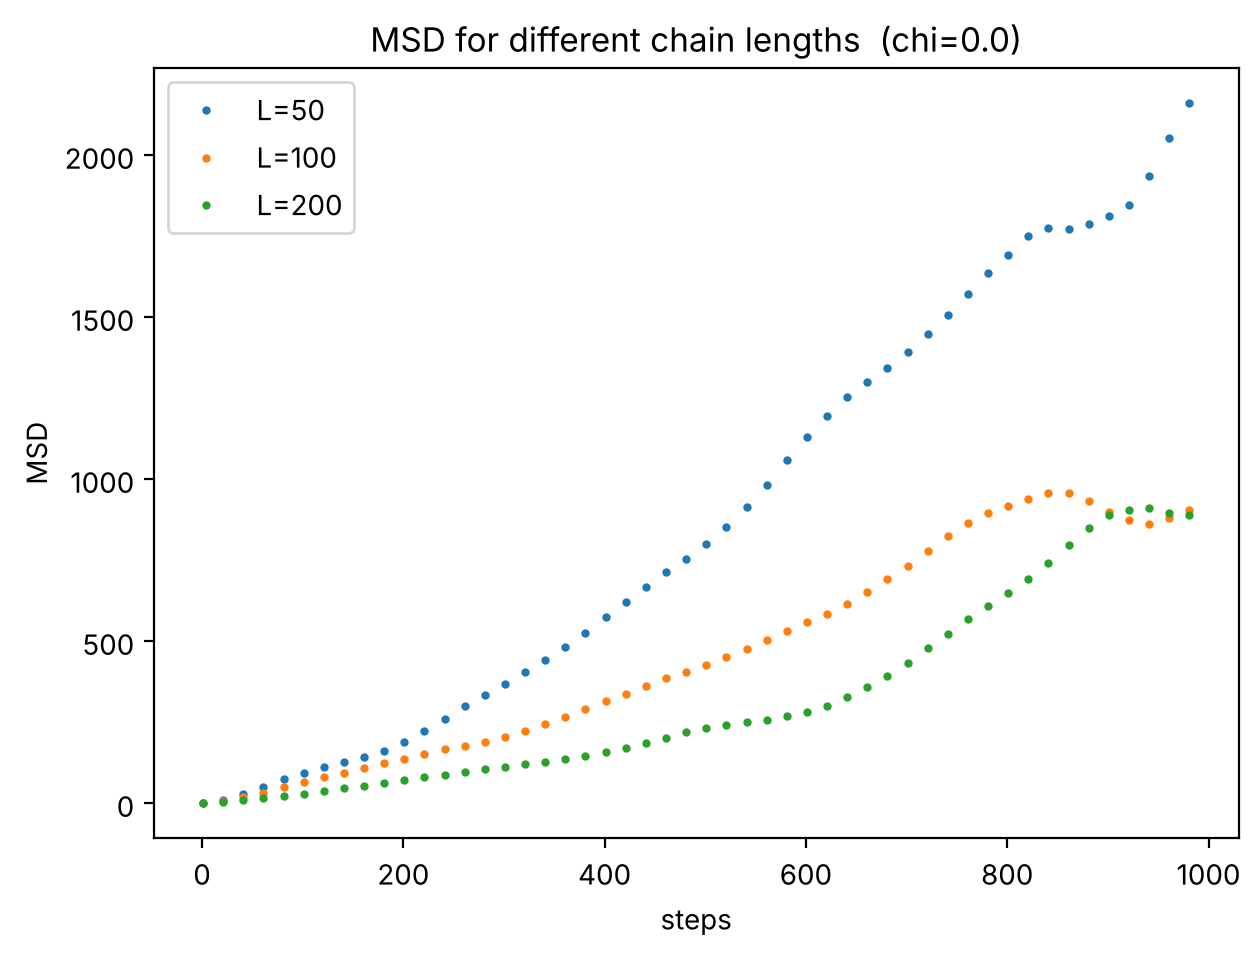

chi=-0.5 done


chi=0 done


chi=0.5 done


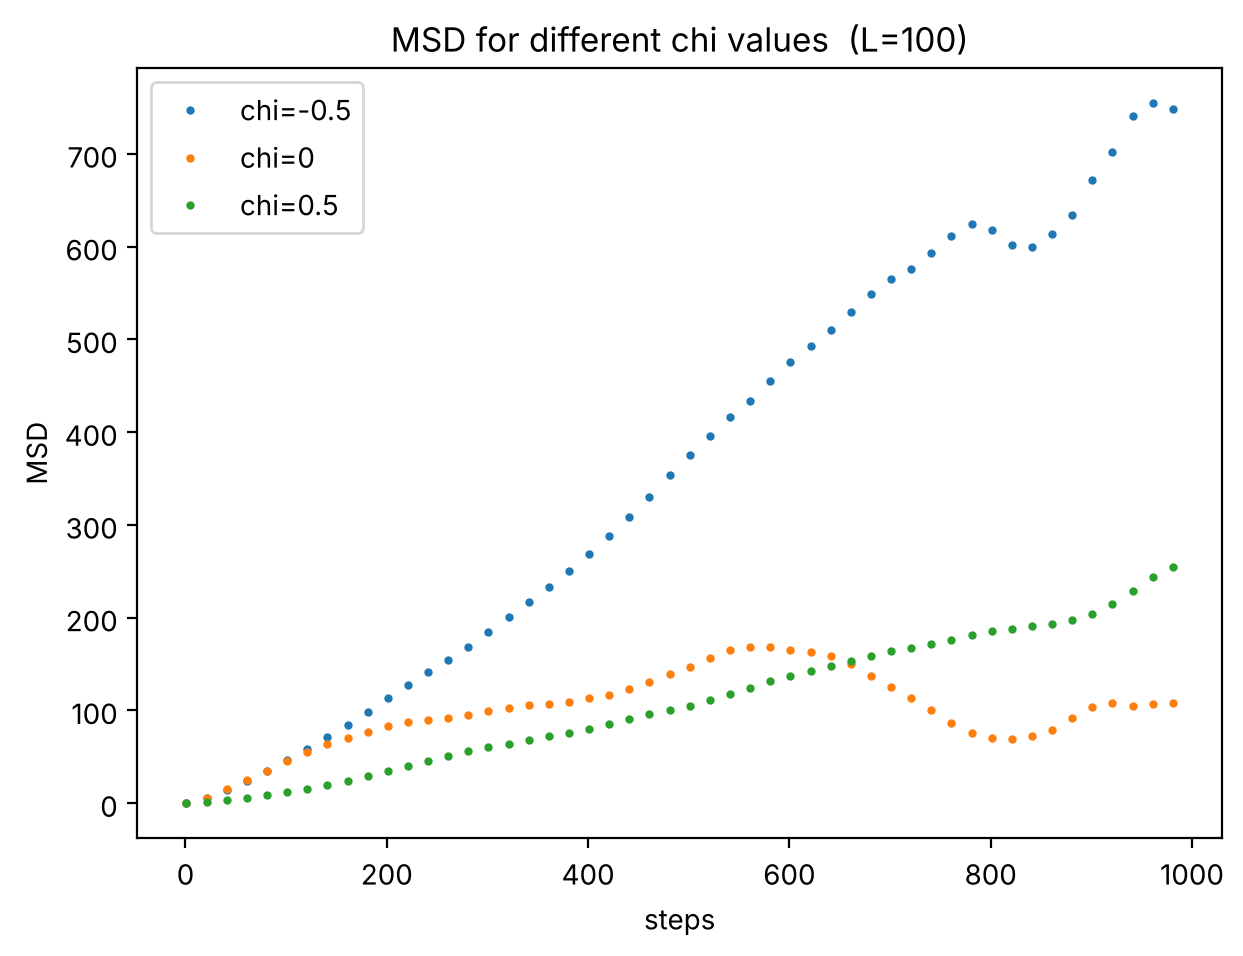

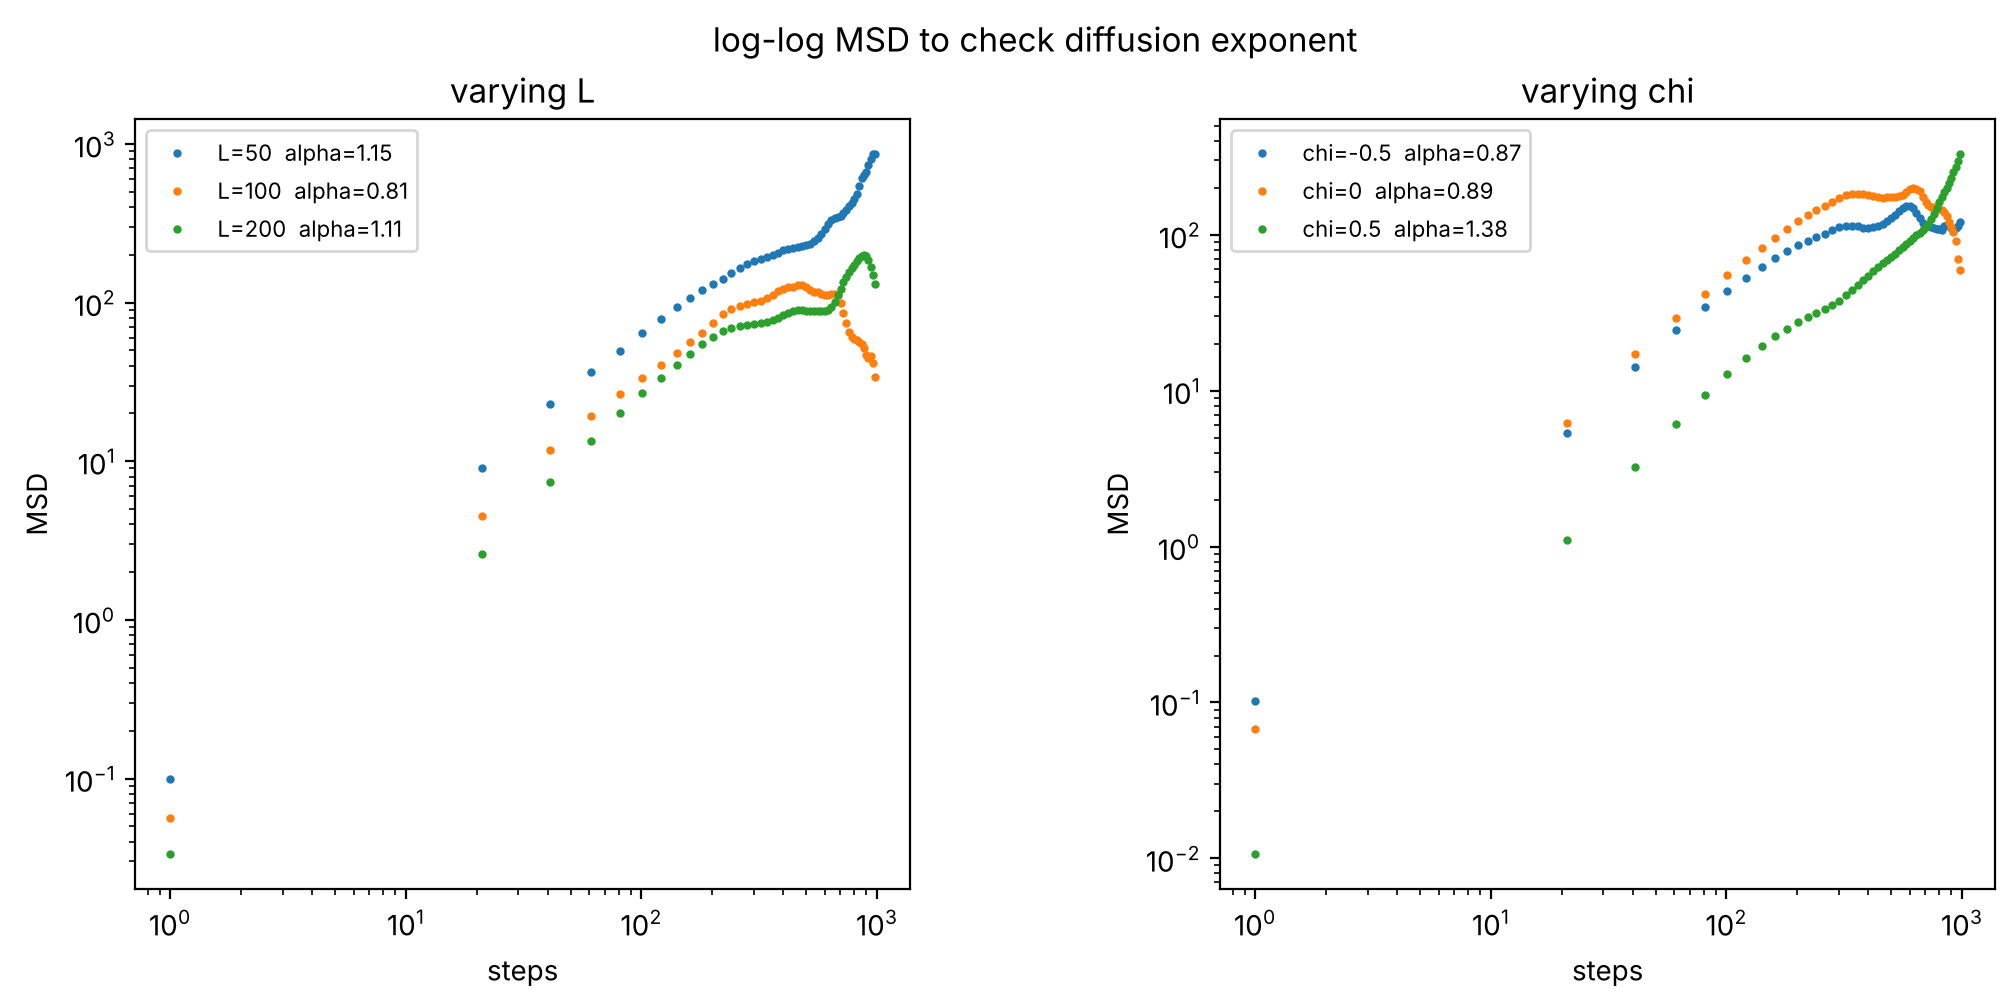

In [2]:
N = 1000  # simulation steps, more steps = better MSD statistics
chi_fixed = 0.0  # using chi=0 as a neutral starting point
lengths = [50, 100, 200]

fig1, ax1 = plt.subplots(figsize=(7, 5))
ax1.set_title(f'MSD for different chain lengths  (chi={chi_fixed})')

for L in lengths:
    # generate a starting chain and run the diffusion
    ol_chain = pf2.WLC_chain_OL(L, chi=chi_fixed)
    cm_simulation = np.zeros((N, 3), np.float64)

    for step in tqdm(range(N)):
        ol_chain = pf2.DiffusionStep(ol_chain, chi_fixed)
        cm_simulation[step] = pf2.g_radius(ol_chain)[1]  # store center of mass

    # compute MSD from the center of mass trajectory
    tau, msd, _, _, _ = pf2.MSD_SingleTrace(cm_simulation, tau=20)
    ax1.plot(tau, msd, 'o', ms=2, label=f'L={L}')
    print(f'L={L} done')

ax1.set_xlabel('steps')
ax1.set_ylabel('MSD')
ax1.legend()
plt.subplots_adjust(wspace=0.4)
plt.show()

# --- part 2: does MSD depend on chi? ---
# now keep L fixed and change chi
# chi controls chain stiffness so i expect it to affect how the chain moves

L_fixed = 100
chi_values = [-0.5, 0, 0.5]

fig2, ax2 = plt.subplots(figsize=(7, 5))
ax2.set_title(f'MSD for different chi values  (L={L_fixed})')

for chi in chi_values:
    ol_chain = pf2.WLC_chain_OL(L_fixed, chi=chi)
    cm_simulation = np.zeros((N, 3), np.float64)

    for step in tqdm(range(N)):
        ol_chain = pf2.DiffusionStep(ol_chain, chi)
        cm_simulation[step] = pf2.g_radius(ol_chain)[1]

    tau, msd, _, _, _ = pf2.MSD_SingleTrace(cm_simulation, tau=20)
    ax2.plot(tau, msd, 'o', ms=2, label=f'chi={chi}')
    print(f'chi={chi} done')

ax2.set_xlabel('steps')
ax2.set_ylabel('MSD')
ax2.legend()
plt.subplots_adjust(wspace=0.4)
plt.show()

# the MSD should grow linearly with time for normal diffusion (MSD ~ t)
# i can check this by fitting a line and seeing if the slope is close to 1
# doing this on a log-log plot: slope = diffusion exponent alpha

fig3, axes3 = plt.subplots(1, 2, figsize=(12, 5))
fig3.suptitle('log-log MSD to check diffusion exponent')

for L in lengths:
    ol_chain = pf2.WLC_chain_OL(L, chi=chi_fixed)
    cm_simulation = np.zeros((N, 3), np.float64)
    for step in range(N):
        ol_chain = pf2.DiffusionStep(ol_chain, chi_fixed)
        cm_simulation[step] = pf2.g_radius(ol_chain)[1]
    tau, msd, _, _, _ = pf2.MSD_SingleTrace(cm_simulation, tau=20)
    alpha = np.polyfit(np.log(tau), np.log(msd), 1)[0]
    axes3[0].plot(tau, msd, 'o', ms=2, label=f'L={L}  alpha={alpha:.2f}')

axes3[0].set_xscale('log')
axes3[0].set_yscale('log')
axes3[0].set_xlabel('steps')
axes3[0].set_ylabel('MSD')
axes3[0].set_title('varying L')
axes3[0].legend(fontsize=8)

for chi in chi_values:
    ol_chain = pf2.WLC_chain_OL(L_fixed, chi=chi)
    cm_simulation = np.zeros((N, 3), np.float64)
    for step in range(N):
        ol_chain = pf2.DiffusionStep(ol_chain, chi)
        cm_simulation[step] = pf2.g_radius(ol_chain)[1]
    tau, msd, _, _, _ = pf2.MSD_SingleTrace(cm_simulation, tau=20)
    alpha = np.polyfit(np.log(tau), np.log(msd), 1)[0]
    axes3[1].plot(tau, msd, 'o', ms=2, label=f'chi={chi}  alpha={alpha:.2f}')

axes3[1].set_xscale('log')
axes3[1].set_yscale('log')
axes3[1].set_xlabel('steps')
axes3[1].set_ylabel('MSD')
axes3[1].set_title('varying chi')
axes3[1].legend(fontsize=8)

plt.subplots_adjust(wspace=0.4)
plt.show()

I ran diffusion simulations and tracked the center of mass over time to compute the MSD. I did it in two parts — first fixed chi and varied the chain length, then fixed L and varied chi. Each condition is a single run of 1000 steps, and the log-log figure uses a new run for each condition.

The most reliable part of the MSD is at short lag times, because there it is averaged over many pairs of points. In that range the MSD clearly decreases with the chain length: in the log-log figure it roughly halves each time the length doubles (L=50, 100, 200). So longer chains diffuse more slowly, approximately like 1/L. For chi, the chains with chi=-0.5 and chi=0 move about the same at short times, while the stiffer chain (chi=0.5) moves several times less. Part of this is built into the simulation, because the size of the trial moves in `DiffusionStep` gets smaller when chi increases.

At long lag times the curves are not reliable. They bend, cross each other and even go down, and two runs with the same parameters give quite different results: for L=50 the MSD at the largest lag is about 2100 in the first figure and about 850 in the log-log figure. The fitted exponents alpha scatter between 0.8 and 1.4 with no trend in L or in chi. They are around 1, which is the value for normal diffusion, but to measure alpha or a diffusion coefficient properly I would need longer runs and an average over several chains.

Q2: Polymer diffusion in a confined volume. A polymer chain is generated in a confined volume (slab or tube) which shape and size can be determined by you and let diffuse in the selected volume. Study how the limited available space affect diffusion and the chain conformations with respect to the free diffusion of assignment (1).

free diffusion done


slab diffusion done


tube diffusion done


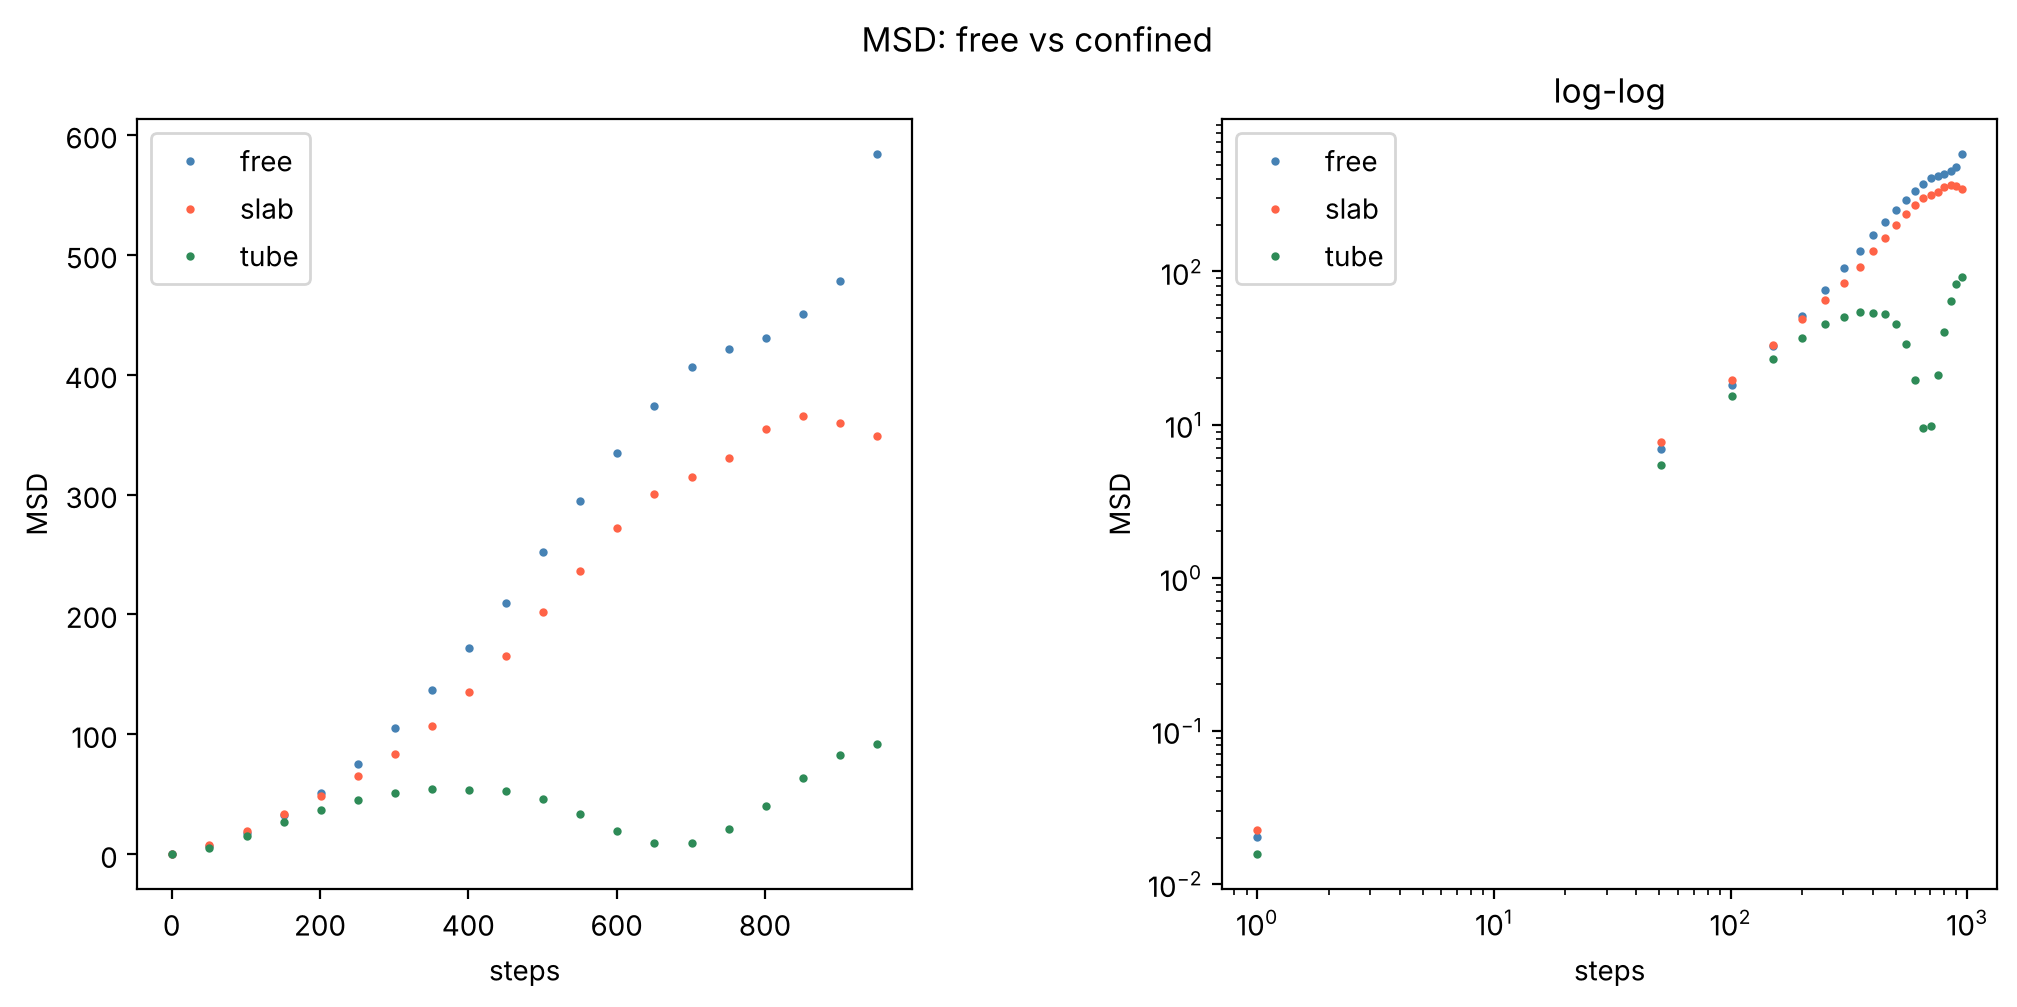

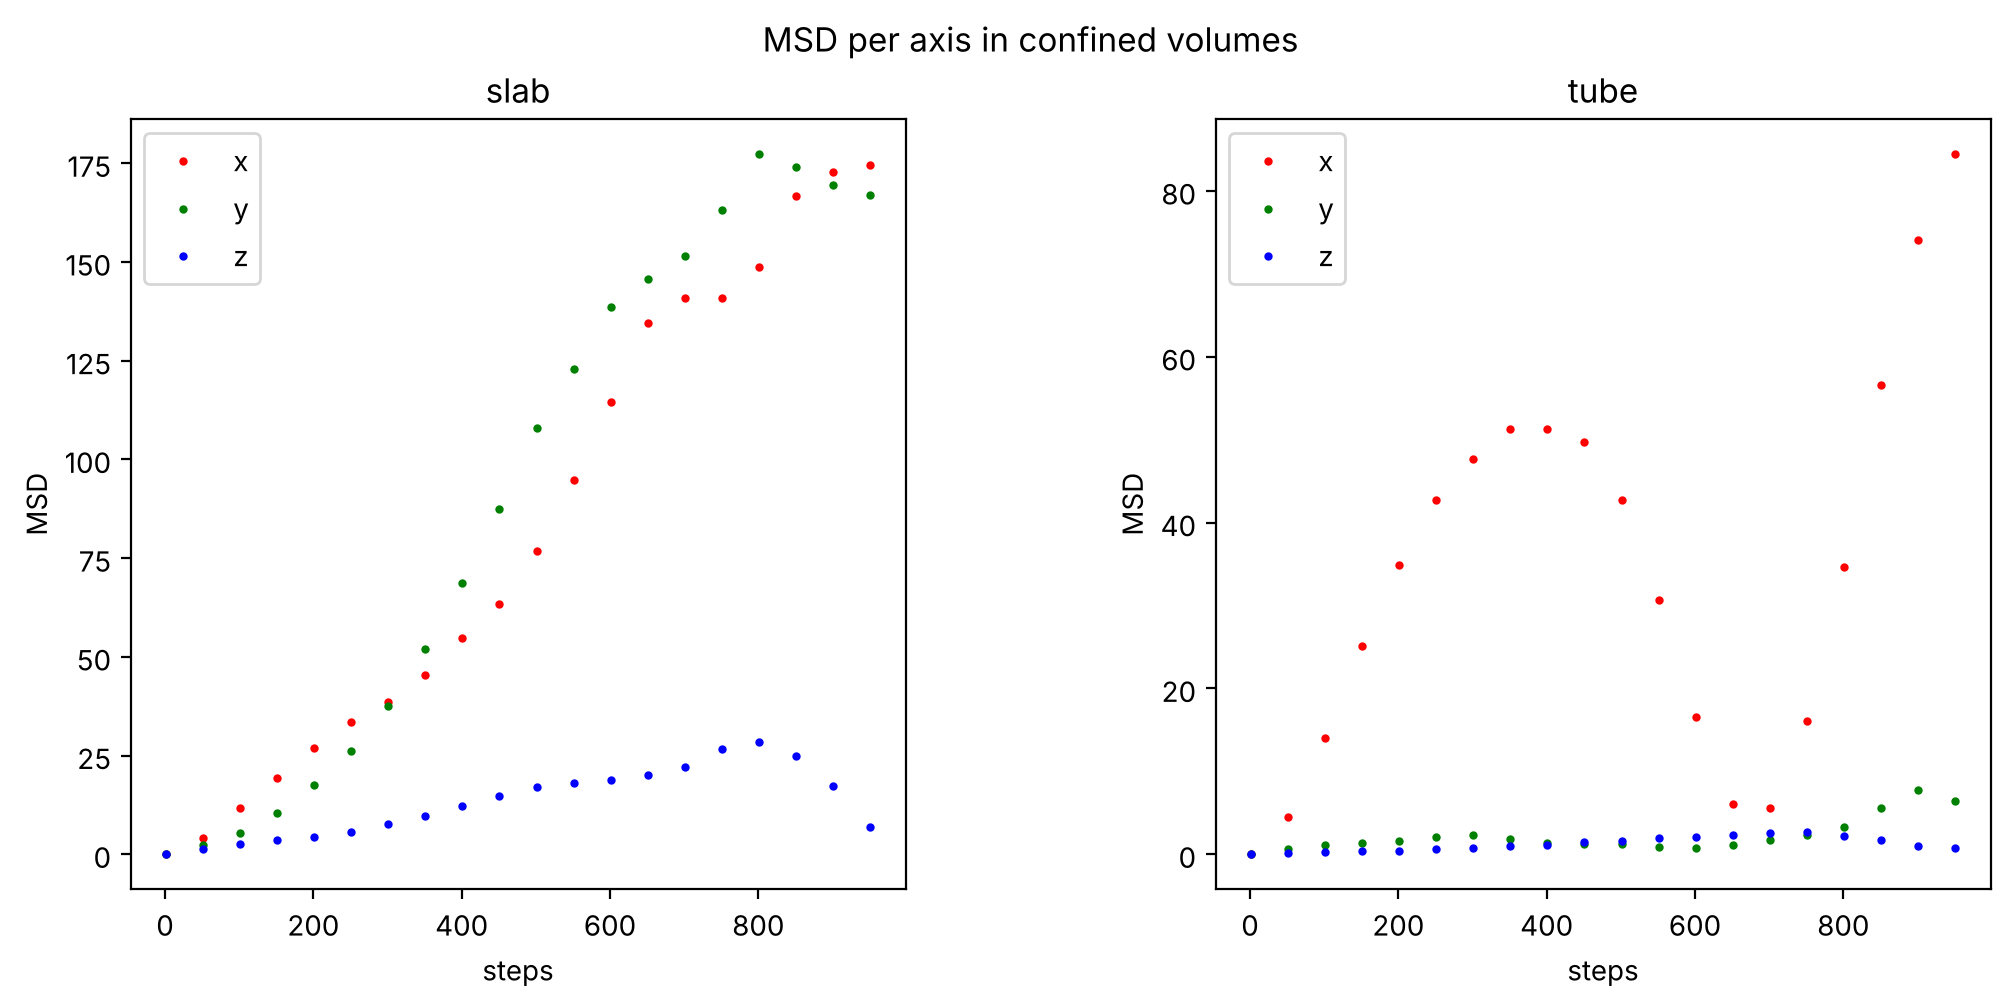

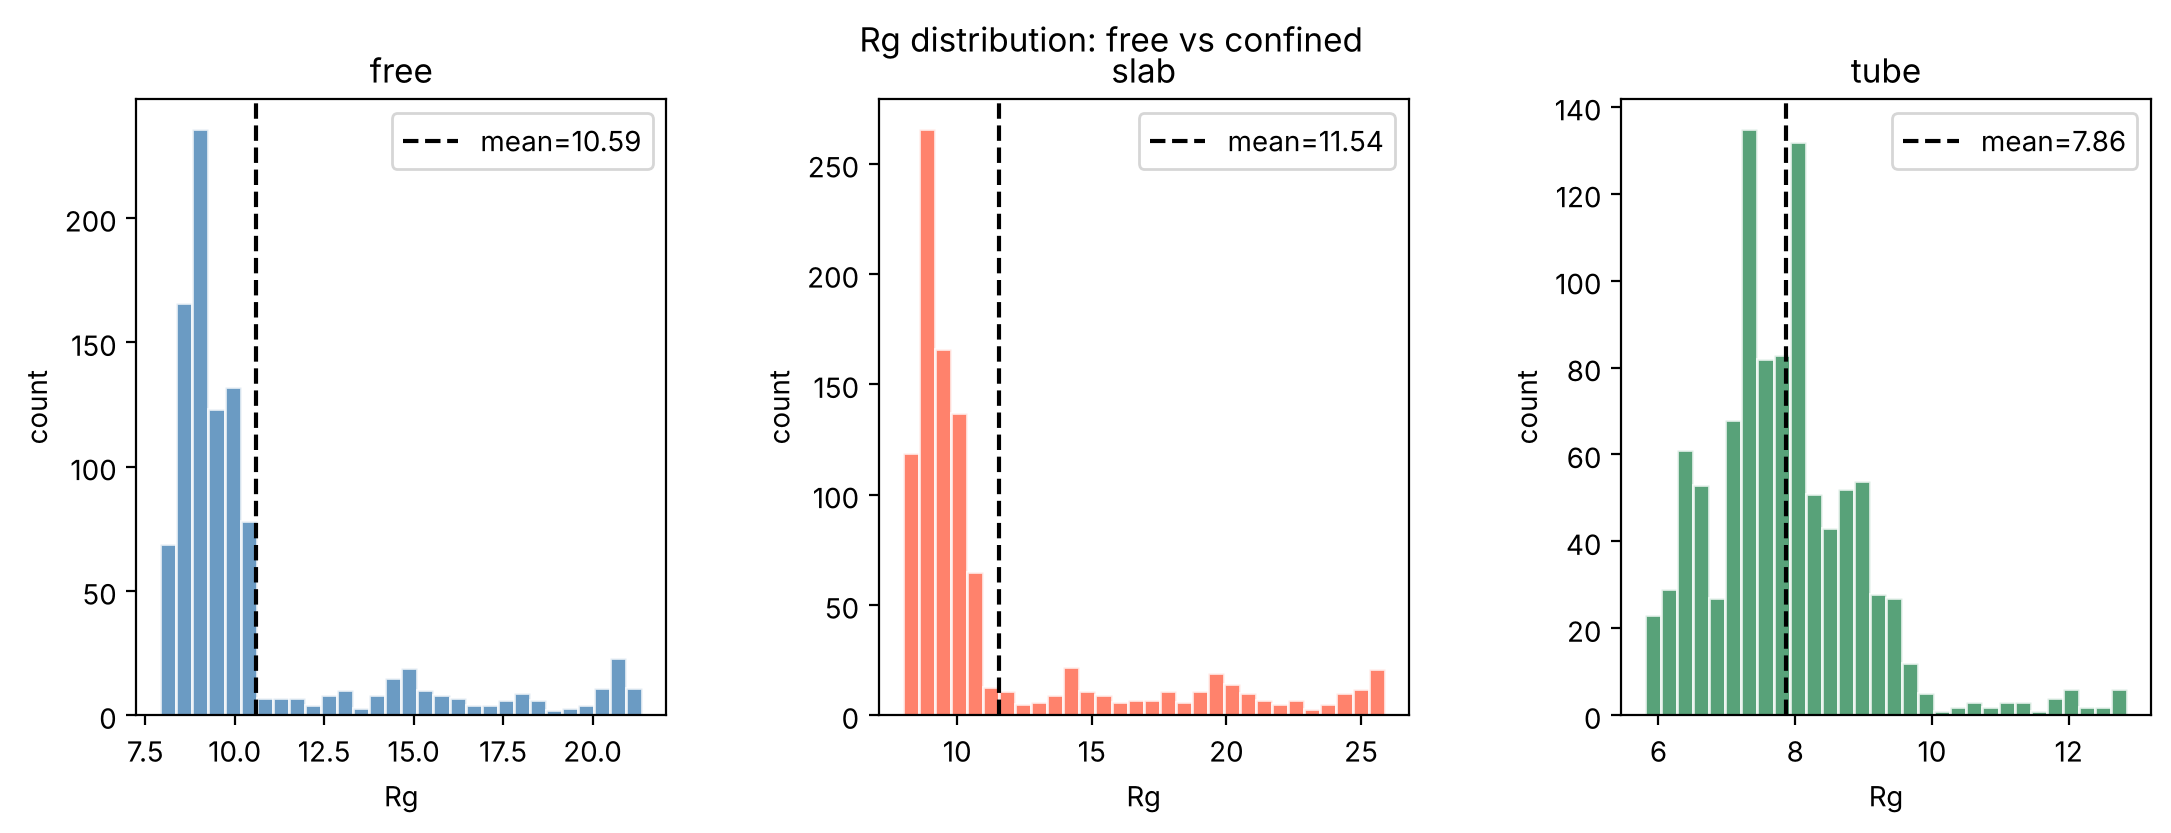

mean Rg  ->  free=10.59  slab=11.54  tube=7.86


In [3]:
L = 200
chi_param = 0.2
N = 1000

ol_chain_free = pf2.WLC_chain_OL(L, chi=chi_param)
cm_free = np.zeros((N, 3), np.float64)
Rg_free = np.zeros(N, np.float64)

for step in tqdm(range(N)):
    ol_chain_free = pf2.DiffusionStep(ol_chain_free, chi_param)
    cm_free[step] = pf2.g_radius(ol_chain_free)[1]
    Rg_free[step] = pf2.g_radius(ol_chain_free)[0]

print('free diffusion done')

v_slab, faces_slab, edges_slab, shape_slab = pf2.parallelepiped(300, 100, 30)
ol_chain_slab = pf2.WLC_chain_OL(L, chi=chi_param, volume_edges=edges_slab, volume_shape=shape_slab)
cm_slab = np.zeros((N, 3), np.float64)
Rg_slab = np.zeros(N, np.float64)

for step in tqdm(range(N)):
    ol_chain_slab = pf2.DiffusionStep(ol_chain_slab, chi_param, volume_edges=edges_slab, volume_shape=shape_slab)
    cm_slab[step] = pf2.g_radius(ol_chain_slab)[1]
    Rg_slab[step] = pf2.g_radius(ol_chain_slab)[0]

print('slab diffusion done')

v_tube, faces_tube, edges_tube, shape_tube = pf2.cylinder(200, 7)
ol_chain_tube = pf2.WLC_chain_OL(L, chi=chi_param, volume_edges=edges_tube, volume_shape=shape_tube)
cm_tube = np.zeros((N, 3), np.float64)
Rg_tube = np.zeros(N, np.float64)

for step in tqdm(range(N)):
    ol_chain_tube = pf2.DiffusionStep(ol_chain_tube, chi_param, volume_edges=edges_tube, volume_shape=shape_tube)
    cm_tube[step] = pf2.g_radius(ol_chain_tube)[1]
    Rg_tube[step] = pf2.g_radius(ol_chain_tube)[0]

print('tube diffusion done')

tau_free, msd_free, msd_x_free, msd_y_free, msd_z_free = pf2.MSD_SingleTrace(cm_free, tau=50)
tau_slab, msd_slab, msd_x_slab, msd_y_slab, msd_z_slab = pf2.MSD_SingleTrace(cm_slab, tau=50)
tau_tube, msd_tube, msd_x_tube, msd_y_tube, msd_z_tube = pf2.MSD_SingleTrace(cm_tube, tau=50)


fig1, axes1 = plt.subplots(1, 2, figsize=(12, 5))
fig1.suptitle('MSD: free vs confined')

for ax in axes1:
    ax.plot(tau_free, msd_free, 'o', ms=2, color='steelblue', label='free')
    ax.plot(tau_slab, msd_slab, 'o', ms=2, color='tomato',    label='slab')
    ax.plot(tau_tube, msd_tube, 'o', ms=2, color='seagreen',  label='tube')
    ax.set_xlabel('steps')
    ax.set_ylabel('MSD')
    ax.legend()

axes1[1].set_xscale('log')
axes1[1].set_yscale('log')
axes1[1].set_title('log-log')

plt.subplots_adjust(wspace=0.4)
plt.show()


fig2, axes2 = plt.subplots(1, 2, figsize=(12, 5))
fig2.suptitle('MSD per axis in confined volumes')

for tau, mx, my, mz, title, ax in zip(
        [tau_slab, tau_tube],
        [msd_x_slab, msd_x_tube],
        [msd_y_slab, msd_y_tube],
        [msd_z_slab, msd_z_tube],
        ['slab', 'tube'],
        axes2):
    ax.plot(tau, mx, 'o', ms=2, color='r', label='x')
    ax.plot(tau, my, 'o', ms=2, color='g', label='y')
    ax.plot(tau, mz, 'o', ms=2, color='b', label='z')
    ax.set_title(title)
    ax.set_xlabel('steps')
    ax.set_ylabel('MSD')
    ax.legend()

plt.subplots_adjust(wspace=0.4)
plt.show()

fig3, axes3 = plt.subplots(1, 3, figsize=(13, 4))
fig3.suptitle('Rg distribution: free vs confined')

for ax, data, title, color in zip(axes3,
                                   [Rg_free, Rg_slab, Rg_tube],
                                   ['free', 'slab', 'tube'],
                                   ['steelblue', 'tomato', 'seagreen']):
    ax.hist(data, bins=30, color=color, edgecolor='white', alpha=0.8)
    ax.axvline(np.mean(data), color='k', linestyle='--', label=f'mean={np.mean(data):.2f}')
    ax.set_title(title)
    ax.set_xlabel('Rg')
    ax.set_ylabel('count')
    ax.legend()

plt.subplots_adjust(wspace=0.4)
plt.show()

print(f'mean Rg  ->  free={np.mean(Rg_free):.2f}  slab={np.mean(Rg_slab):.2f}  tube={np.mean(Rg_tube):.2f}')

For question 2 I ran the same diffusion simulation as question 1 but this time inside confined volumes — a slab (300 × 100 × 30) and a tube (length 200, radius 7) — and compared them with free diffusion (L=200, chi=0.2). I tracked the center of mass and Rg at every step for all three cases.

The per-axis MSD shows the confinement clearly. In the slab the MSD in x and y keeps growing (to about 170), while in z, the thin direction, it stays below 30 and stops growing. In the tube the MSD in y and z stays below 10, so the chain can basically only move along the axis of the tube (x). The total MSD in the tube is much smaller than for free diffusion (below 100 against about 580 at the largest lag). For the slab the total MSD is somewhat lower than for the free chain (about 350 against 580), but from question 1 I know that two single runs can differ by this much, so I cannot say that the slab slows down the diffusion along x and y. The x curve in the tube goes up, down and up again, which shows once more that one run of 1000 steps is too short for the long lag times.

For the chain size, the Rg distributions of the free chain and of the chain in the slab both have their peak at about 9, so the slab does not change the size of the chain. This makes sense because the slab is thicker (30) than the chain. Both distributions have a tail up to Rg of 20–25, most likely from the beginning of the run when the chain is still relaxing from its starting conformation, and this tail is why the mean values (10.6 and 11.5) are above the peak. In the tube the chain is clearly more compact (mean Rg 7.9), because the radius of the tube (7) is smaller than the size of the free chain.

Q3: Polymer Elasticity. A polymer chain is fully stretched and then let relax simulating an optical trapping experiment in which the entropic elasticity of the polymer is probed. Study how the chi parameter changes the elasticity of the chain. How fast the chain reaches conformational equilibrium? How can you define equilibrium conformations from the gyration radius and the end-to-end distance?

chi=-0.6 done


chi=-0.2 done


chi=0.2 done


chi=0.6 done


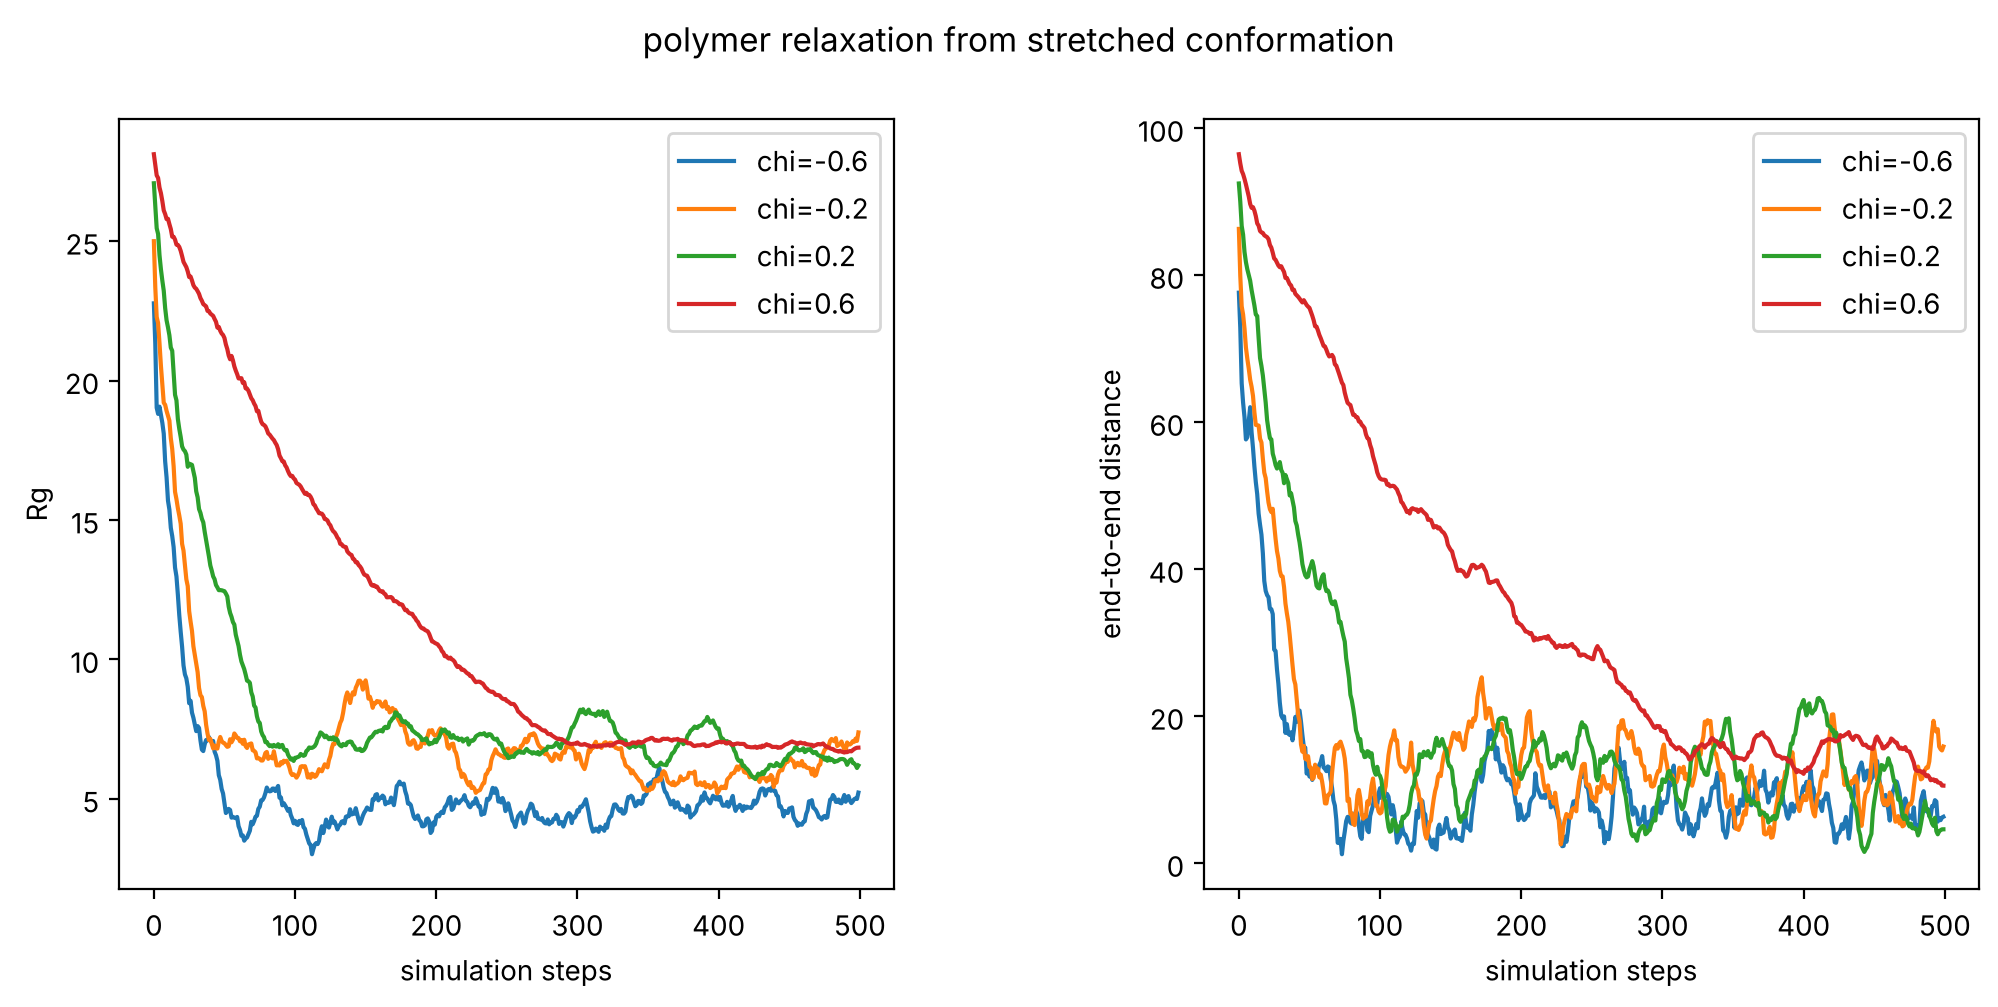


equilibrium values (mean of last 200 steps):


chi=-0.6  Rg=4.63+-0.67  EtE=9.90+-4.26


chi=-0.2  Rg=6.63+-0.80  EtE=12.02+-3.25


chi=0.2  Rg=6.20+-0.76  EtE=9.67+-4.97


chi=0.6  Rg=7.21+-0.29  EtE=15.86+-3.56


In [4]:
L = 100
chi_values = [-0.6, -0.2, 0.2, 0.6]
N = 500

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('polymer relaxation from stretched conformation')

for chi_param in chi_values:
    ol_chain = pf2.InitRod(L) 

    Rg_simulation = np.zeros(N, np.float64)
    EtE_simulation = np.zeros(N, np.float64)

    for step in tqdm(range(N)):
        ol_chain = pf2.DiffusionStep(ol_chain, chi_param)
        Rg_simulation[step] = pf2.g_radius(ol_chain)[0]
        EtE_simulation[step] = pf2.EndToEnd(ol_chain)

    axes[0].plot(np.arange(N), Rg_simulation, label=f'chi={chi_param}')
    axes[1].plot(np.arange(N), EtE_simulation, label=f'chi={chi_param}')
    print(f'chi={chi_param} done')

axes[0].set_xlabel('simulation steps')
axes[0].set_ylabel('Rg')
axes[0].legend()

axes[1].set_xlabel('simulation steps')
axes[1].set_ylabel('end-to-end distance')
axes[1].legend()

plt.subplots_adjust(wspace=0.4)
plt.show()

print('\nequilibrium values (mean of last 200 steps):')
for chi_param in chi_values:
    ol_chain = pf2.InitRod(L)
    Rg_simulation = np.zeros(N, np.float64)
    EtE_simulation = np.zeros(N, np.float64)
    for step in range(N):
        ol_chain = pf2.DiffusionStep(ol_chain, chi_param)
        Rg_simulation[step] = pf2.g_radius(ol_chain)[0]
        EtE_simulation[step] = pf2.EndToEnd(ol_chain)
    print(f'chi={chi_param}  Rg={np.mean(Rg_simulation[-200:]):.2f}+-{np.std(Rg_simulation[-200:]):.2f}  EtE={np.mean(EtE_simulation[-200:]):.2f}+-{np.std(EtE_simulation[-200:]):.2f}')


I started from a fully stretched chain using InitRod and let it relax for 500 steps for different chi values. I tracked both Rg and the end-to-end distance over time. Both start high (Rg about 23–28, end-to-end distance about 80–97 for 100 monomers) and decrease until they only fluctuate around a constant value. This is how I define equilibrium here: Rg and the end-to-end distance no longer drift, they only fluctuate around their mean. Nothing pulls the chain together in this simulation. It contracts only because there are many more coiled conformations than stretched ones, which is the entropic elasticity of the polymer.

The relaxation time depends clearly on chi. The flexible chains (chi=-0.6 and -0.2) reach the plateau in about 50–70 steps, chi=0.2 needs about 100 steps, and the stiffest chain (chi=0.6) needs about 300 steps for Rg, and its end-to-end distance may still be decreasing at the end of the run.

For the plateau values (mean of the last 200 steps, computed from a second run with the same parameters) the most flexible chain is the most compact (Rg=4.6) and the stiffest one is the largest (Rg=7.2, end-to-end distance 15.9), as expected. The two middle values are not in order (6.6 for chi=-0.2 and 6.2 for chi=0.2), and the fluctuations of the end-to-end distance (±3 to ±5) are as large as the differences between the chains. So the trend with chi is visible only between the extremes; to resolve it I would need longer runs.